# Librerías de Python para IA y estadística

## Métodos Estadísticos para IA · Especialización en Inteligencia Artificial

**Material complementario de la Unidad 1**

**Objetivos:** reconocer la función de cada librería, elegir herramientas según la pregunta y comprender cómo se integran en un análisis.

### Recorrido

1. Qué es una librería y para qué sirve.
2. Preparación e imports.
3. NumPy y pandas.
4. SciPy y `scipy.stats`.
5. Matplotlib y Seaborn.
6. Statsmodels.
7. Scikit-learn y su comparación con Statsmodels.
8. TensorFlow y Keras.
9. Flujo de trabajo y documentación.

## 1. ¿Qué es una librería?
Una librería reúne código reutilizable: funciones, clases y otras herramientas para resolver tareas. Un **módulo** es una unidad de código que podemos importar. Un **paquete** organiza módulos y subpaquetes. En el uso cotidiano se suele hablar de “librerías” para referirse a estas herramientas.

Permiten ahorrar tiempo, aprovechar implementaciones optimizadas y acceder a funciones especializadas. Sus comunidades ofrecen documentación, ejemplos y soporte. Muchas se integran entre sí y funcionan en diferentes sistemas, aunque la compatibilidad depende de las versiones y dependencias.

Usar una función requiere comprender qué calcula, qué supuestos utiliza y qué significa su salida. La disponibilidad de una herramienta no garantiza que sea adecuada para nuestros datos.

### Mapa del ecosistema
| Librería | Función principal en este material | Ejemplo |
|---|---|---|
| NumPy | Cálculo numérico y arrays | Media y desviación estándar |
| pandas | Tablas, limpieza, filtrado y agrupación | Resumen por grupo |
| SciPy / scipy.stats | Cálculo científico, distribuciones y tests | Probabilidades y cuantiles |
| Matplotlib | Construcción y personalización de gráficos | Histograma |
| Seaborn | Visualización estadística sobre Matplotlib | Diagrama de cajas |
| Statsmodels | Modelos e inferencia estadística | Coeficientes e intervalos de confianza |
| Scikit-learn | Aprendizaje automático y evaluación predictiva | Regresión y error en test |
| TensorFlow | Cálculo con tensores y aprendizaje automático | Entrenamiento de redes |
| Keras | API de alto nivel para aprendizaje profundo | Definición de capas |

## 2. Preparación del entorno
La siguiente celda comprueba las dependencias y solo instala las que falten. Una instalación necesita acceso a Internet. En un entorno que ya las tenga, pasa directamente a los imports.

**Instalar** incorpora un paquete al entorno. **Importar** permite utilizarlo en la sesión. Los alias `np`, `pd`, `plt`, `sns` y `sm` son convenciones, y se pueden elegir otros.

In [1]:
import importlib.util
import subprocess
import sys

paquetes = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy",
            "matplotlib": "matplotlib", "seaborn": "seaborn",
            "statsmodels": "statsmodels", "sklearn": "scikit-learn"}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *faltantes])
print("Dependencias disponibles.")

Dependencias disponibles.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.distributions.empirical_distribution import ECDF
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from IPython.display import display
from importlib.metadata import version

sns.set_theme(style="whitegrid")
rng = np.random.default_rng(2026)
display(pd.DataFrame({"Paquete": list(paquetes.values()),
                      "Versión": [version(p) for p in paquetes.values()]}))

,Paquete,Versión
0,numpy,2.1.3
1,pandas,2.2.3
2,scipy,1.16.3
3,matplotlib,3.10.0
4,seaborn,0.13.2
5,statsmodels,0.15.0
6,scikit-learn,1.6.1


## 3. NumPy: cálculo numérico
NumPy (*Numerical Python*) proporciona arrays de una o varias dimensiones. Permite operar con vectores y matrices, aplicar funciones matemáticas y generar números aleatorios. Las operaciones vectorizadas expresan cálculos sobre muchos valores sin escribir un bucle explícito.

En este ejemplo, un array contiene ocho tiempos de respuesta en milisegundos. Calculamos medidas descriptivas y convertimos las unidades.

In [ ]:
tiempos = np.array([95, 102, 98, 110, 105, 99, 115, 101], dtype=float)
print("Tiempos (ms):", tiempos)
print("Tiempos (s):", tiempos / 1000)
print(f"Media: {np.mean(tiempos):.2f} ms")
print(f"Mediana: {np.median(tiempos):.2f} ms")
print(f"Desviación estándar muestral: {np.std(tiempos, ddof=1):.2f} ms")
print("Cuartiles:", np.quantile(tiempos, [0.25, 0.5, 0.75]))

Tiempos (ms): [ 95. 102.  98. 110. 105.  99. 115. 101.]
Tiempos (s): [0.095 0.102 0.098 0.11  0.105 0.099 0.115 0.101]
Media: 103.12 ms
Mediana: 101.50 ms
Desviación estándar muestral: 6.62 ms
Cuartiles: [ 98.75 101.5  106.25]


### Un conjunto de datos común para el resto del notebook
Simularemos 160 ejecuciones de un algoritmo. La carga de procesamiento se mide entre 1 y 10 unidades. El tiempo depende de esa carga y de un error aleatorio normal. La columna `servidor` representa una etiqueta de grupo asignada al azar, sin efecto introducido sobre el tiempo.

La semilla permite reproducir los resultados dentro del mismo entorno. Estos datos son didácticos: no representan mediciones reales.

In [ ]:
n = 160
carga = rng.uniform(1, 10, size=n)
tiempo_ms = 40 + 8 * carga + rng.normal(0, 7, size=n)
datos = pd.DataFrame({"carga": carga, "tiempo_ms": tiempo_ms,
                      "servidor": rng.choice(["A", "B"], size=n)})
display(datos.head())

,carga,tiempo_ms,servidor
0,2.610413,54.917677,B
1,6.759218,100.018252,B
2,5.205416,71.657955,A
3,4.334505,71.502105,A
4,4.194256,57.783903,B


## 4. pandas: organización y exploración de datos
pandas ofrece **Series** para datos de una dimensión y **DataFrames** para tablas con filas y columnas. Facilita importar archivos CSV o Excel, seleccionar observaciones, tratar valores faltantes y obtener resúmenes por grupo. También dispone de herramientas para series temporales.

Aquí exploramos la tabla creada con NumPy. `describe()` resume las columnas numéricas, `isna()` detecta valores faltantes y `groupby()` agrupa observaciones. En un archivo propio, la lectura podría hacerse con `pd.read_csv("archivo.csv")` después de subirlo a Colab.

In [ ]:
display(datos.describe())
print("Valores faltantes por columna:")
print(datos.isna().sum())
display(datos.groupby("servidor")["tiempo_ms"].agg(["count", "mean", "median", "std"]))
print("Primeras ejecuciones con carga mayor que 8:")
display(datos.loc[datos["carga"] > 8, ["carga", "tiempo_ms"]].head())

Valores faltantes por columna:
carga        0
tiempo_ms    0
servidor     0
dtype: int64
Primeras ejecuciones con carga mayor que 8:


,carga,tiempo_ms
count,160.000000,160.000000
mean,5.556023,85.112484
std,2.379072,20.533796
min,1.016221,42.628667
25%,3.792231,71.414423
50%,5.640563,84.105503
75%,7.270525,101.081019
max,9.907626,138.097119


,count,mean,median,std
servidor,,,,
A,78,86.177951,84.604876,19.383650
B,82,84.098991,83.727343,21.641462


,carga,tiempo_ms
5,8.114664,108.395043
6,9.146295,118.368595
10,9.702660,111.027344
11,9.278651,132.873993
15,8.433057,101.306397


## 5. SciPy y su módulo estadístico
SciPy se construye sobre NumPy y reúne herramientas de cálculo científico: optimización, integración, interpolación, álgebra lineal, funciones especiales, transformadas y procesamiento de señales, entre otras.

Para este curso nos interesa especialmente **`scipy.stats`**, que incluye distribuciones discretas y continuas, estadísticos descriptivos, correlaciones y tests de hipótesis.

### Distribuciones de probabilidad
| Método | Operación |
|---|---|
| `pmf(k)` | Probabilidad puntual en distribuciones discretas |
| `pdf(x)` | Densidad en distribuciones continuas |
| `cdf(x)` | Probabilidad acumulada $P(X\leq x)$ |
| `sf(x)` | Probabilidad $P(X>x)$ |
| `ppf(q)` | Cuantil asociado a la probabilidad acumulada $q$ |
| `rvs(size=...)` | Generación de valores aleatorios |

`stats.norm`, `stats.t`, `stats.chi2`, `stats.binom` y `stats.poisson` son algunos ejemplos. En una variable continua, la densidad evaluada en un punto no es la probabilidad de ese valor.

In [ ]:
# Tiempo hipotético normal: media 100 ms y desviación estándar 15 ms.
distribucion = stats.norm(loc=100, scale=15)
print(f"P(T ≤ 120 ms) = {distribucion.cdf(120):.4f}")
print(f"P(90 < T ≤ 110 ms) = {distribucion.cdf(110) - distribucion.cdf(90):.4f}")
print(f"Percentil 95 = {distribucion.ppf(0.95):.2f} ms")
print(f"P(K = 3), Poisson con media 4 = {stats.poisson(mu=4).pmf(3):.4f}")
print("Cinco valores normales simulados:", distribucion.rvs(size=5, random_state=rng))

P(T ≤ 120 ms) = 0.9088
P(90 < T ≤ 110 ms) = 0.4950
Percentil 95 = 124.67 ms
P(K = 3), Poisson con media 4 = 0.1954
Cinco valores normales simulados: [121.92911798 109.12297806 111.90152315  95.72748269  92.8876691 ]


### Correlación y un primer test
La correlación de Pearson cuantifica la asociación lineal. Su valor está entre −1 y 1. Una asociación fuerte no prueba causalidad.

El test de Welch compara las medias de dos grupos independientes sin exigir igualdad de varianzas. Su hipótesis nula es $H_0:\mu_A=\mu_B$. Las observaciones deben ser independientes. Con muestras pequeñas, la forma de la distribución y los valores extremos requieren especial atención.

El valor *p* expresa, bajo $H_0$ y los supuestos del test, cuán incompatibles son los resultados con esa hipótesis. No es la probabilidad de que $H_0$ sea verdadera. Un resultado no significativo tampoco demuestra igualdad de medias. Estos temas se desarrollarán en la unidad de inferencia.

In [ ]:
correlacion = stats.pearsonr(datos["carga"], datos["tiempo_ms"])
grupo_a = datos.loc[datos["servidor"] == "A", "tiempo_ms"]
grupo_b = datos.loc[datos["servidor"] == "B", "tiempo_ms"]
welch = stats.ttest_ind(grupo_a, grupo_b, equal_var=False)
print(f"Pearson: r = {correlacion.statistic:.3f}, p = {correlacion.pvalue:.3g}")
print(f"Welch: t = {welch.statistic:.3f}, p = {welch.pvalue:.3f}")
print("Interpretar junto con el diseño, los supuestos y la magnitud de la diferencia.")

Pearson: r = 0.931, p = 6.41e-71
Welch: t = 0.641, p = 0.523
Interpretar junto con el diseño, los supuestos y la magnitud de la diferencia.


## 6. Matplotlib y Seaborn: descripción gráfica
**Matplotlib** permite crear figuras y controlar ejes, etiquetas, títulos y estilos. Es útil tanto para gráficos simples como para composiciones personalizadas.

**Seaborn** se apoya en Matplotlib y facilita gráficos estadísticos directamente desde tablas: histogramas, dispersión, diagramas de cajas y mapas de calor, entre otros.

El histograma resume la distribución del tiempo. El diagrama de cajas compara grupos. La dispersión muestra la asociación entre carga y tiempo. Son preguntas diferentes y requieren representaciones distintas. El tiempo marginal mezcla ejecuciones con cargas distintas, por lo que no tiene por qué ser normal aunque el error simulado sí lo sea.

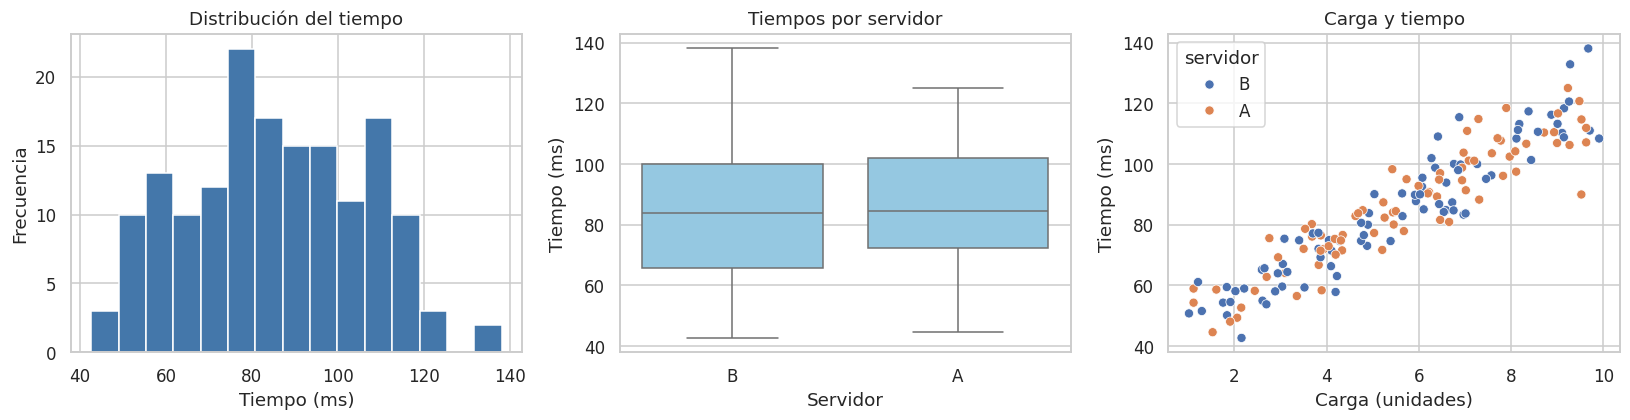

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(datos["tiempo_ms"], bins=15, color="#4477AA", edgecolor="white")
axes[0].set(title="Distribución del tiempo", xlabel="Tiempo (ms)", ylabel="Frecuencia")
sns.boxplot(data=datos, x="servidor", y="tiempo_ms", ax=axes[1], color="#88CCEE")
axes[1].set(title="Tiempos por servidor", xlabel="Servidor", ylabel="Tiempo (ms)")
sns.scatterplot(data=datos, x="carga", y="tiempo_ms", hue="servidor", ax=axes[2])
axes[2].set(title="Carga y tiempo", xlabel="Carga (unidades)", ylabel="Tiempo (ms)")
plt.tight_layout()
plt.show()

## 7. Statsmodels: modelado e inferencia
Statsmodels permite ajustar modelos estadísticos y obtener coeficientes, errores estándar, intervalos de confianza y valores *p*. Incluye regresión lineal y otros modelos, tests, series temporales y herramientas de diagnóstico.

Ajustaremos el modelo $T_i=\beta_0+\beta_1 C_i+\varepsilon_i$, donde $C$ es la carga y $T$ el tiempo. `sm.add_constant()` incorpora el intercepto: `sm.OLS` no lo agrega automáticamente.

La pendiente estima cuánto cambia el tiempo medio por cada unidad adicional de carga. El intercepto corresponde a carga cero, fuera del rango simulado, y debe interpretarse con cuidado.

La inferencia clásica requiere supuestos sobre los errores y el modelo. En esta simulación los errores son independientes, normales y de varianza constante. En datos reales debemos evaluar esos supuestos y el diseño.

In [ ]:
X = sm.add_constant(datos[["carga"]])
ajuste = sm.OLS(datos["tiempo_ms"], X).fit()
print(ajuste.summary())
intervalos = ajuste.conf_int(alpha=0.05)
display(pd.DataFrame({"Coeficiente": ajuste.params,
                      "Error estándar": ajuste.bse,
                      "IC 95% inferior": intervalos[0],
                      "IC 95% superior": intervalos[1],
                      "Valor p": ajuste.pvalues}))

                            OLS Regression Results                            
Dep. Variable:              tiempo_ms   R-squared:                       0.866
Model:                            OLS   Adj. R-squared:                  0.865
Method:                 Least Squares   F-statistic:                     1023.
Date:                Mon, 05 Oct 2026   Prob (F-statistic):           6.41e-71
Time:                        14:38:00   Log-Likelihood:                -549.11
No. Observations:                 160   AIC:                             1102.
Df Residuals:                     158   BIC:                             1108.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         40.4801      1.517     26.685      0.0

,Coeficiente,Error estándar,IC 95% inferior,IC 95% superior,Valor p
const,40.480112,1.516958,37.483981,43.476243,2.056226e-60
carga,8.033151,0.251109,7.537187,8.529115,6.414432e-71


### Herramientas conectadas con la Unidad 1
La **ECDF** muestra la proporción observada de tiempos menores o iguales a cada umbral. El gráfico **Q-Q** compara cuantiles de los residuos con cuantiles normales. Los puntos cercanos a una recta son compatibles visualmente con normalidad. El gráfico de residuos frente al ajuste ayuda a explorar curvatura y cambios de dispersión. Ningún gráfico aislado verifica todos los supuestos.

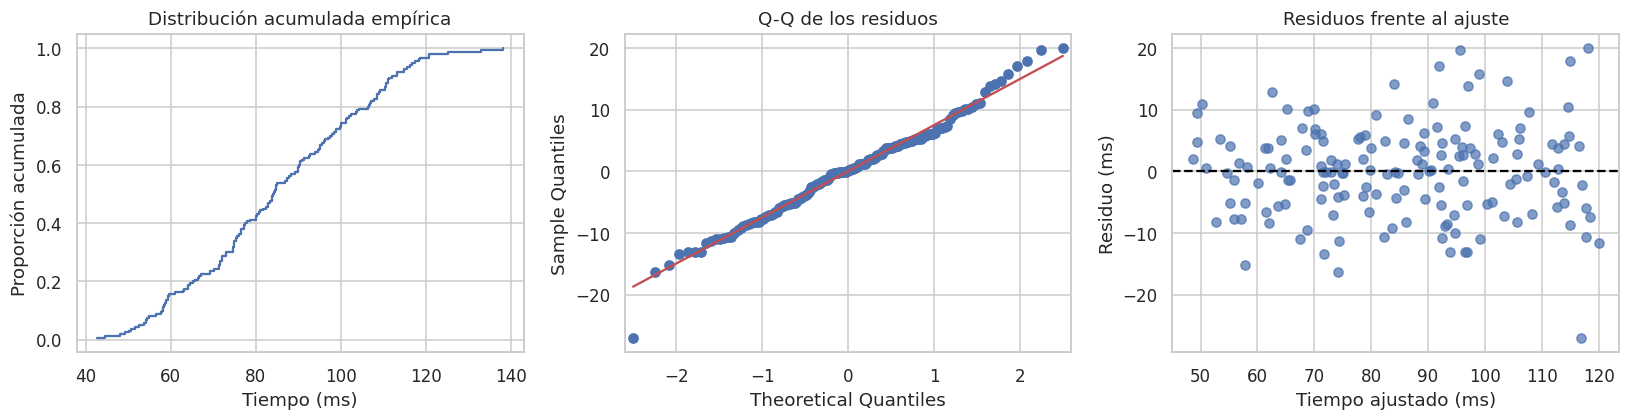

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ecdf = ECDF(datos["tiempo_ms"])
x = np.sort(datos["tiempo_ms"].to_numpy())
axes[0].step(x, ecdf(x), where="post")
axes[0].set(title="Distribución acumulada empírica", xlabel="Tiempo (ms)", ylabel="Proporción acumulada")
sm.qqplot(ajuste.resid, line="s", ax=axes[1])
axes[1].set_title("Q-Q de los residuos")
axes[2].scatter(ajuste.fittedvalues, ajuste.resid, alpha=0.7)
axes[2].axhline(0, color="black", linestyle="--")
axes[2].set(title="Residuos frente al ajuste", xlabel="Tiempo ajustado (ms)", ylabel="Residuo (ms)")
plt.tight_layout()
plt.show()

## 8. Scikit-learn: aprendizaje automático
Scikit-learn incluye clasificación, regresión, agrupamiento y reducción de dimensionalidad. También ofrece preprocesamiento, selección de modelos, validación y métricas de evaluación. Sus estimadores siguen una interfaz común: `fit()` ajusta el modelo y `predict()` genera predicciones.

En este ejemplo separamos entrenamiento y test **antes de ajustar**. El modelo aprende solo del entrenamiento y evaluamos sobre observaciones reservadas. La partición aleatoria es adecuada para esta simulación independiente. Las series temporales o los datos agrupados requieren otros esquemas.

El RMSE mide el error en las unidades del tiempo. $R^2$ compara con la predicción constante igual a la media del test y puede ser negativo. Una única partición da una evaluación inicial. No debemos usar el test repetidamente para elegir modelos.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    datos[["carga"]], datos["tiempo_ms"], test_size=0.25, random_state=2026)
modelo = LinearRegression()
modelo.fit(X_train, y_train)
predicciones = modelo.predict(X_test)
print(f"Intercepto: {modelo.intercept_:.3f}")
print(f"Pendiente: {modelo.coef_[0]:.3f}")
print(f"RMSE en test: {np.sqrt(mean_squared_error(y_test, predicciones)):.3f} ms")
print(f"R² en test: {r2_score(y_test, predicciones):.3f}")

Intercepto: 40.551
Pendiente: 8.003
RMSE en test: 6.949 ms
R² en test: 0.864


### Statsmodels y Scikit-learn: énfasis diferentes
| Aspecto | Statsmodels | Scikit-learn |
|---|---|---|
| Énfasis habitual | Inferencia e interpretación estadística | Predicción y evaluación de modelos |
| Salidas frecuentes | Coeficientes, errores estándar, intervalos y valores p | Predicciones y métricas calculadas sobre conjuntos de evaluación |
| Herramientas | Resúmenes y diagnósticos estadísticos | Pipelines, preprocesamiento y validación cruzada |
| Intercepto en el ejemplo | Se agrega con `sm.add_constant` | `LinearRegression` lo incluye por defecto |

Ambas pueden ajustar una regresión lineal. Sus usos se superponen y la elección depende del objetivo. Los coeficientes anteriores pueden diferir porque utilizamos todos los datos en Statsmodels y solo el entrenamiento en Scikit-learn. Para comprobar la coincidencia de mínimos cuadrados, ajustamos ambas sobre el mismo entrenamiento.

In [ ]:
ajuste_train = sm.OLS(y_train, sm.add_constant(X_train)).fit()
display(pd.DataFrame({"Statsmodels": [ajuste_train.params["const"], ajuste_train.params["carga"]],
                      "Scikit-learn": [modelo.intercept_, modelo.coef_[0]]},
                     index=["Intercepto", "Pendiente"]))

,Statsmodels,Scikit-learn
Intercepto,40.550658,40.550658
Pendiente,8.002878,8.002878


## 9. TensorFlow y Keras: panorama de aprendizaje profundo
**TensorFlow** es una plataforma de código abierto impulsada por Google para cálculo con tensores y aprendizaje automático. Incluye diferenciación automática y herramientas para entrenar y desplegar modelos, con soporte para aceleradores compatibles.

**Keras** ofrece una API de alto nivel para definir y entrenar redes neuronales. Keras 3 puede utilizar distintos backends, entre ellos TensorFlow, JAX y PyTorch. Conviene consultar la documentación de la versión elegida al adaptar ejemplos anteriores.

El siguiente fragmento es solo ilustrativo. No necesitamos instalar estas herramientas ni entrenar una red para completar este notebook.

```python
import keras
from keras import layers

red = keras.Sequential([
    keras.Input(shape=(4,)),
    layers.Dense(8, activation="relu"),
    layers.Dense(1)  # Salida para regresión
])
red.compile(optimizer="adam", loss="mse")
# red.fit(X_train, y_train, epochs=20)
```

Este fragmento supone un backend configurado y entradas de cuatro características. No se aplica directamente al ejemplo de una sola variable de este notebook.

## 10. ¿Cómo se integran en un análisis?
Las herramientas pueden participar en varias etapas. El orden depende de la pregunta y del diseño.

| Etapa | Herramientas habituales | Aplicación en el notebook |
|---|---|---|
| Organizar y revisar los datos | pandas | DataFrame, faltantes y grupos |
| Calcular y simular | NumPy | Arrays y generación de datos |
| Explorar visualmente | Matplotlib y Seaborn | Histograma, cajas y dispersión |
| Trabajar con probabilidad y tests | scipy.stats | CDF, cuantiles, correlación y Welch |
| Ajustar e interpretar modelos | Statsmodels | OLS, intervalos y residuos |
| Evaluar predicción | Scikit-learn | Partición train/test y RMSE |

### Buenas prácticas
- Leer la documentación de los argumentos y las salidas.
- Conservar unidades y nombres de columnas claros.
- Revisar valores faltantes antes de calcular o ajustar.
- Distinguir la variabilidad de los datos del error estándar de un estimador.
- Interpretar valores p junto con supuestos, intervalos y tamaños de efecto.
- En aprendizaje automático, ajustar las transformaciones usando el entrenamiento para evitar filtraciones de información.
- Registrar semillas y versiones para facilitar la reproducción.

## 11. Documentación oficial

- [NumPy](https://numpy.org/doc/stable/)
- [pandas](https://pandas.pydata.org/docs/)
- [SciPy](https://docs.scipy.org/doc/scipy/)
- [scipy.stats: funciones estadísticas](https://docs.scipy.org/doc/scipy/reference/stats.html)
- [Matplotlib](https://matplotlib.org/stable/)
- [Seaborn](https://seaborn.pydata.org/)
- [Statsmodels: primeros pasos](https://www.statsmodels.org/stable/gettingstarted.html)
- [Scikit-learn](https://scikit-learn.org/stable/)
- [TensorFlow](https://www.tensorflow.org/)
- [Keras 3 y sus backends](https://keras.io/keras_3/)
